# avito-candidates-generator

Ноутбук локально создаёт `answer.csv` с 50 кандидатами на каждый запрос. Внешние API, GPU и предобученные модели не используются.

## Схема решения

BM25 по заголовку, параметрам и описанию + символьный TF-IDF заголовка. Глобальные и локальные списки объединяются RRF. Затем item query profile добавляет в хвост три объявления, для которых в train встречались похожие запросы.

In [1]:
from pathlib import Path
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

DATA_DIR = Path('data') if Path('data').exists() else Path('../data')
TOP_K = 50
RETRIEVAL_K = 180
SEED = 42
np.random.seed(SEED)

## Данные

Train — пары «запрос — выбранное объявление». В бенчмарке известны запросы и корпус: нужно вернуть до 50 объявлений, среди которых окажется выбранное.

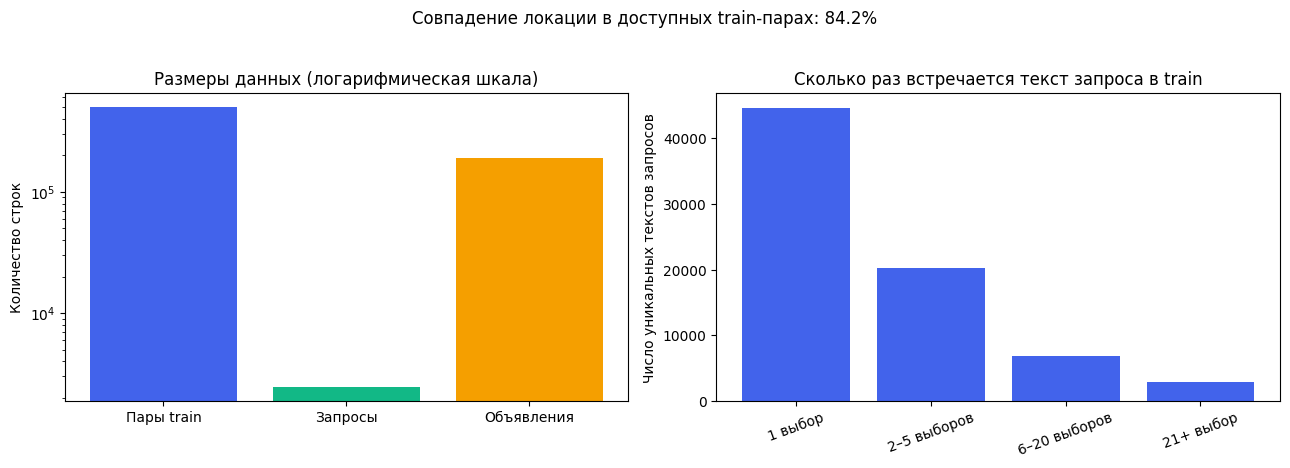

,Факт,Значение
0,Уникальных текстов запросов в train,"74,529"
1,"Benchmark-запросов, уже встречавшихся в train",37.0%
2,Train-пар с объявлением в корпусе,"33,010"
3,Совпадение локации в этих парах,84.2%


In [2]:
train_stats = pd.read_parquet(DATA_DIR / 'train.parquet', columns=['search_query', 'search_location_id', 'item_location_id', 'item_id'])
benchmark_queries = pd.read_parquet(DATA_DIR / 'benchmark_queries.parquet', columns=['query_id', 'search_query'])
corpus_ids = set(pd.read_parquet(DATA_DIR / 'benchmark_items.parquet', columns=['item_id'])['item_id'])
benchmark_queries_count, benchmark_items_count = len(benchmark_queries), len(corpus_ids)
query_frequency = train_stats['search_query'].value_counts()
frequency_buckets = pd.Series({
    '1 выбор': (query_frequency == 1).sum(),
    '2–5 выборов': query_frequency.between(2, 5).sum(),
    '6–20 выборов': query_frequency.between(6, 20).sum(),
    '21+ выбор': (query_frequency >= 21).sum(),
})
overlap_train = train_stats[train_stats['item_id'].isin(corpus_ids)]
location_match = (overlap_train['search_location_id'] == overlap_train['item_location_id']).mean()
seen_query_share = benchmark_queries['search_query'].isin(set(train_stats['search_query'])).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(['Пары train', 'Запросы', 'Объявления'], [len(train_stats), benchmark_queries_count, benchmark_items_count], color=['#4263eb', '#12b886', '#f59f00'])
axes[0].set_yscale('log')
axes[0].set_title('Размеры данных (логарифмическая шкала)')
axes[0].set_ylabel('Количество строк')

axes[1].bar(frequency_buckets.index, frequency_buckets.values, color='#4263eb')
axes[1].set_title('Сколько раз встречается текст запроса в train')
axes[1].set_ylabel('Число уникальных текстов запросов')
axes[1].tick_params(axis='x', rotation=20)
fig.suptitle(f'Совпадение локации в доступных train-парах: {location_match:.1%}', y=1.03)
fig.tight_layout()
plt.show()

pd.DataFrame({
    'Факт': ['Уникальных текстов запросов в train', 'Benchmark-запросов, уже встречавшихся в train', 'Train-пар с объявлением в корпусе', 'Совпадение локации в этих парах'],
    'Значение': [f'{train_stats.search_query.nunique():,}', f'{seen_query_share:.1%}', f'{len(overlap_train):,}', f'{location_match:.1%}'],
})

## Причина выбора подхода

Короткие запросы хорошо покрывает лексический поиск: BM25 ловит слова и словосочетания, char TF-IDF ловит словоформы и опечатки. Item query profile использует train как обучающие данные: к тексту объявления добавляются реальные запросы пользователей, которые выбрали это объявление. Три profile-кандидата заменяют только хвост списка, поэтому основной lexical-сигнал сохраняется.

## Подготовка текстов и индексов

BM25 получает заголовок, параметры и ограниченное описание. Заголовок и параметры повторяются, поскольку для короткого запроса они надёжнее длинного описания.

In [3]:
def clean_text(value: object) -> str:
    text = '' if pd.isna(value) else str(value).lower().replace('ё', 'е')
    return re.sub(r'\s+', ' ', text).strip()


def make_item_text(frame: pd.DataFrame) -> tuple[list[str], list[str]]:
    word_text, char_text = [], []
    columns = ['item_title_raw', 'item_infm_params_text', 'item_description_raw']
    for title, params, description in frame[columns].itertuples(index=False):
        title, params, description = (clean_text(value) for value in (title, params, description))
        word_text.append(' '.join([title] * 2 + [params[:350]] * 2 + [description[:220]]))
        char_text.append(title[:240])
    return word_text, char_text


def make_query_text(frame: pd.DataFrame) -> list[str]:
    result = []
    for query, filters in frame[['search_query', 'search_infm_params_text']].itertuples(index=False):
        query, filters = clean_text(query), clean_text(filters)
        result.append(' '.join([query] * 4 + [filters] * 2))
    return result


def top_indices(scores: np.ndarray, k: int) -> np.ndarray:
    k = min(k, len(scores))
    selected = np.argpartition(scores, -k)[-k:]
    return selected[np.argsort(scores[selected])[::-1]]


items = pd.read_parquet(DATA_DIR / 'benchmark_items.parquet')
queries = pd.read_parquet(DATA_DIR / 'benchmark_queries.parquet')
word_text, char_text = make_item_text(items)

bm25_vectorizer = CountVectorizer(token_pattern=r'(?u)\b\w+\b', ngram_range=(1, 2), min_df=2, max_features=300_000, dtype=np.float32)
char_vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, max_features=350_000, sublinear_tf=True, dtype=np.float32)
bm25_matrix = bm25_vectorizer.fit_transform(word_text).tocsr()
document_lengths = np.asarray(bm25_matrix.sum(axis=1)).ravel()
document_frequency = np.bincount(bm25_matrix.indices, minlength=bm25_matrix.shape[1])
idf = np.log1p((len(items) - document_frequency + 0.5) / (document_frequency + 0.5))
k1, b = 1.5, 0.75
length_norm = k1 * (1 - b + b * document_lengths / document_lengths.mean())
row_index = np.repeat(np.arange(bm25_matrix.shape[0]), np.diff(bm25_matrix.indptr))
bm25_matrix.data *= (k1 + 1) / (bm25_matrix.data + length_norm[row_index])
bm25_matrix.data *= idf[bm25_matrix.indices]
char_matrix = char_vectorizer.fit_transform(char_text).tocsr()
item_ids = items['item_id'].astype(str).to_numpy()
item_locations = items['item_location_id'].to_numpy()
valid_ids = set(item_ids)

## Лексический retrieval

Для каждого запроса строятся четыре ранжированных списка: BM25 и char TF-IDF по всему корпусу, затем те же методы внутри точной локации. RRF объединяет списки в 50 кандидатов.

In [4]:
def retrieve(query_frame: pd.DataFrame) -> list[list[str]]:
    query_text = make_query_text(query_frame)
    query_bm25 = bm25_vectorizer.transform(query_text)
    query_char = char_vectorizer.transform(query_text)
    query_bm25.data.fill(1)
    predictions, locations = [], query_frame['search_location_id'].to_numpy()

    for start in range(0, len(query_frame), 32):
        stop = start + 32
        bm25_batch = (query_bm25[start:stop] @ bm25_matrix.T).toarray()
        char_batch = (query_char[start:stop] @ char_matrix.T).toarray()
        for bm25_scores, char_scores, location in zip(bm25_batch, char_batch, locations[start:stop]):
            bm25_global = top_indices(bm25_scores, RETRIEVAL_K)
            char_global = top_indices(char_scores, RETRIEVAL_K)
            local_mask = item_locations == location
            if local_mask.any():
                local_positions = np.flatnonzero(local_mask)
                bm25_local = local_positions[top_indices(bm25_scores[local_mask], RETRIEVAL_K)]
                char_local = local_positions[top_indices(char_scores[local_mask], RETRIEVAL_K)]
            else:
                bm25_local = char_local = np.empty(0, dtype=np.int64)
            fusion = np.zeros(len(item_ids), dtype=np.float32)
            for ranking in (bm25_global, char_global, bm25_local, char_local):
                fusion[ranking] += 1 / (60 + np.arange(len(ranking)))
            candidates = np.unique(np.concatenate([bm25_global, char_global, bm25_local, char_local]))
            scores = fusion[candidates] + 0.012 * (item_locations[candidates] == location)
            predictions.append(item_ids[candidates[top_indices(scores, TOP_K)]].tolist())
    return predictions

## Локальная валидация

В holdout берутся 500 нормализованных train-запросов, чьи выбранные объявления есть в benchmark-корпусе. Параметры retrieval фиксированы до оценки.

In [5]:
search_columns = ['search_query', 'search_location_id', 'search_is_delivery_search', 'search_infm_params_text', 'search_category']
train_full = pd.read_parquet(DATA_DIR / 'train.parquet', columns=search_columns + ['item_id'])
train_full['item_id'] = train_full['item_id'].astype(str)
train_full = train_full[train_full['item_id'].isin(valid_ids)].copy()


def strict_key(frame):
    return (
        frame['search_query'].map(clean_text) + '\x1f'
        + frame['search_category'].fillna(-1).astype(str) + '\x1f'
        + frame['search_infm_params_text'].map(clean_text)
    )


train_full['strict_key'] = strict_key(train_full)
history = (train_full.groupby('strict_key', sort=False)['item_id']
           .agg(lambda ids: list(pd.unique(ids))[:3]).to_dict())
groups = (train_full.groupby('strict_key', sort=False)
          .agg(relevant_ids=('item_id', lambda ids: list(pd.unique(ids))),
               search_query=('search_query', 'first'),
               search_location_id=('search_location_id', 'first'),
               search_is_delivery_search=('search_is_delivery_search', 'first'),
               search_infm_params_text=('search_infm_params_text', 'first'),
               search_category=('search_category', 'first'))
          .reset_index())

## Item query profile и формирование ответа

Для каждого объявления собираются до восьми текстов запросов из train. TF-IDF ищет запрос среди этих расширенных текстов. Три profile-кандидата добавляются после первых 47 lexical-кандидатов; повторы удаляются.

In [6]:
def build_profile_index(profile_train):
    queries_by_item = profile_train.groupby('item_id', sort=False)['search_query'].agg(lambda x: ' '.join(pd.unique(x)[:8])).to_dict()
    texts = [text + ' ' + clean_text(queries_by_item.get(item_id, '')) for item_id, text in zip(item_ids, word_text)]
    vectorizer = TfidfVectorizer(token_pattern=r'(?u)\b\w+\b', ngram_range=(1, 2), min_df=2, max_features=300_000, sublinear_tf=True, dtype=np.float32)
    return vectorizer, vectorizer.fit_transform(texts).tocsr()

def profile_retrieve(frame, vectorizer, matrix):
    query_matrix = vectorizer.transform(make_query_text(frame))
    return [item_ids[top_indices(scores, RETRIEVAL_K)].tolist() for scores in (query_matrix @ matrix.T).toarray()]

def merge_profile(lexical, profile, tail_size=3):
    result = []
    for lexical_ids, profile_ids in zip(lexical, profile):
        selected = list(lexical_ids[:TOP_K - tail_size])
        for source in (profile_ids, lexical_ids):
            for item_id in source:
                if item_id not in selected: selected.append(item_id)
                if len(selected) == TOP_K: break
            if len(selected) == TOP_K: break
        result.append(selected)
    return result

profile_vectorizer, profile_matrix = build_profile_index(train_full)
predictions = merge_profile(retrieve(queries), profile_retrieve(queries, profile_vectorizer, profile_matrix))
answer = pd.DataFrame({'query_id': queries['query_id'].astype(str), 'answer': [' '.join(ids) for ids in predictions]})
answer.to_csv('answer.csv', index=False, encoding='utf-8')

## Проверка формата и локальная оценка

Три split по строгим ключам запросов проверяют устойчивость. Для каждого split profile строится только на обучающей части train, поэтому выбранные объявления валидационной части не попадают в его профиль. Проверяется несколько размеров хвоста; в ответе используется лучший средний вариант.

In [7]:
tail_sizes = (1, 2, 3, 5)
rows = []
for seed in (17, 42, 91):
    validation = groups.sample(min(500, len(groups)), random_state=seed)
    fit = train_full[~train_full['strict_key'].isin(set(validation['strict_key']))]
    vectorizer, matrix = build_profile_index(fit)
    frame, relevant = validation[search_columns], validation['relevant_ids']
    lexical = retrieve(frame)
    profile = profile_retrieve(frame, vectorizer, matrix)
    recall = lambda predictions: np.mean([len(set(p) & set(y)) / len(y) for p, y in zip(predictions, relevant)])
    for tail_size in tail_sizes:
        rows.append((seed, tail_size, recall(merge_profile(lexical, profile, tail_size))))

result = pd.DataFrame(rows, columns=['seed', 'Profile ID в хвосте', 'Recall@50'])
table = result.pivot(index='seed', columns='Profile ID в хвосте', values='Recall@50')
display(table)
mean_scores = table.mean()
best_tail_size = int(mean_scores.idxmax())
display(pd.DataFrame({'Profile ID в хвосте': mean_scores.index, 'Средний Recall@50': mean_scores.values}))
print(f'Выбрано Profile ID в хвосте: {best_tail_size}. Средний Recall@50: {mean_scores[best_tail_size]:.6f}')

predictions = merge_profile(retrieve(queries), profile_retrieve(queries, profile_vectorizer, profile_matrix), best_tail_size)
answer = pd.DataFrame({'query_id': queries['query_id'].astype(str), 'answer': [' '.join(ids) for ids in predictions]})
answer.to_csv('answer.csv', index=False, encoding='utf-8')
answer_lists = [value.split() for value in answer['answer']]
if not (len(answer) == len(queries) and answer['query_id'].is_unique and all(len(ids) == TOP_K and len(ids) == len(set(ids)) and set(ids) <= valid_ids for ids in answer_lists)):
    raise ValueError('Некорректный answer.csv')

Profile ID в хвосте,1,2,3,5
seed,,,,
17,0.656585,0.655104,0.658612,0.656235
42,0.607998,0.611819,0.613548,0.610631
91,0.655322,0.660056,0.660556,0.659713


,Profile ID в хвосте,Средний Recall@50
0,1,0.639969
1,2,0.642326
2,3,0.644239
3,5,0.642193


Выбрано Profile ID в хвосте: 3. Средний Recall@50: 0.644239
